<a href="https://colab.research.google.com/github/Emmafraioli/MPM_200_Emma_FRAIOLI/blob/main/Code/assignment_1_will__hummers_survive_FRAIOLI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [8]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [9]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. FRAIOLI!", by = "rabbit")


 _________________________________________ 
< Welcome to Hummingbird HQ, Dr. FRAIOLI! >
 ----------------------------------------- 
     \
      \

      ( )_( )
      (='.'=)
      (^)_(^) [nosig]

In [10]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [11]:
url <- "/Hummingbird_data (1).csv"
data <- read.csv(url)
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `____`.
Now find how many rows and columns `data` has.

In [12]:
# your code here
dim(data)
nrow(data)
ncol(data)

[1] 6908   12

[1] 6908

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [13]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:** character are: Admitted, Disposition_biniary, Place, F_Aid, Species_e, Sex_e, Age_e, season, r, Green_Orange, ID
Numbers are: Brought_in_after
Admited is stored as character, not date format
The one looking like odds are: Admitted, Sex_e and ID

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [14]:
set.seed(0702)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [15]:
# your code here
dim(model_data)

[1] 5000   12

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:** 11 colums are categorical (Admitted, Disposition_biniary, Place, F_Aid, Species_e, Sex_e, Age_e, season, r, Green_Orange, ID ) and 1 is continious (brought_in_after)
ID is not very useful because it's an identifier for each bird and has no biological or predictive value for survival outcomes

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [16]:
write.csv(model_data, "outputs/Hummingbird_data_EmmaFRAIOLI.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [17]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4143
Santa Barbara,66
malibu,791


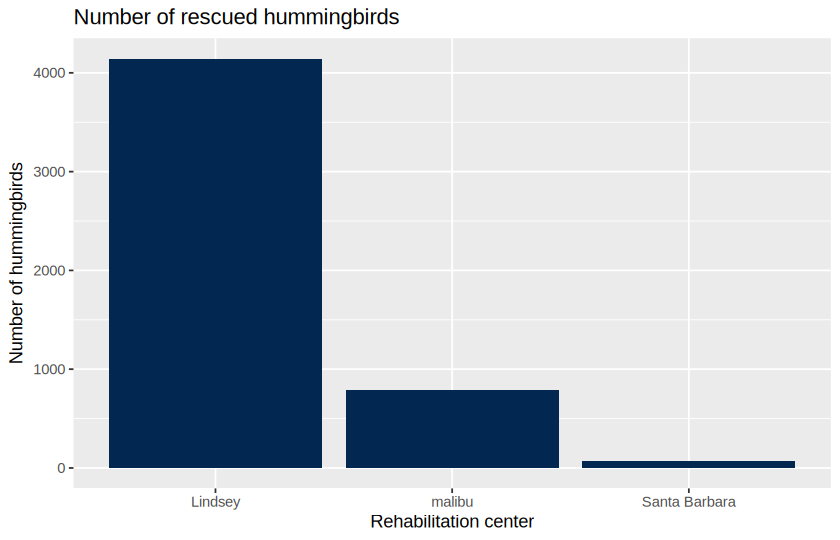

In [18]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [19]:
ggsave("outputs/rehab_counts_YOURNAME.pdf",p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:**
1) rehab <- model_data %>% : create the object named rehab by taking the model_data dataset, the % help passing the data forward to the next operation
2) group_by(Place) %>% : groups the dataset bu the place column
3) summarise(count = n_distinct(ID)): each group are summurised to a single summary row with a new column called count using n-distinct (ID) to count the numbe rof bird ID
4) rehab: print/shows the summary table

5) p <- ggplot(rehab, aes(x = Place, y = count)) +: store ggplot as p using rehab table and maps the rehabilitation number (place) to the x axis and bird count to the y axis
6) geom_col(fill = "#022851") + : adds a bar chart and the number represent the color
7) xlab("Rehabilitation center") +: label the x axis  rehabilitation center
8) ylab("Number of hummingbirds") +: label the y axis number of hummingbirds
9) labs(title = "Number of rescued hummingbirds") : adds the tittle
10) p : shows the finished plot

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:**
yes more birds die at Lindsey, in raw number but not because birds have higher rish of dying there. Raw counts are not enough because they ignore the total number of admission at each center. We should look at proportion or rates if we would like to be fair.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [20]:
df <- model_data %>%
  group_by(F_Aid, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

F_Aid,Disposition_binary,count
<chr>,<chr>,<int>
No,Died,2085
No,Released,1199
Yes,Died,1105
Yes,Released,611


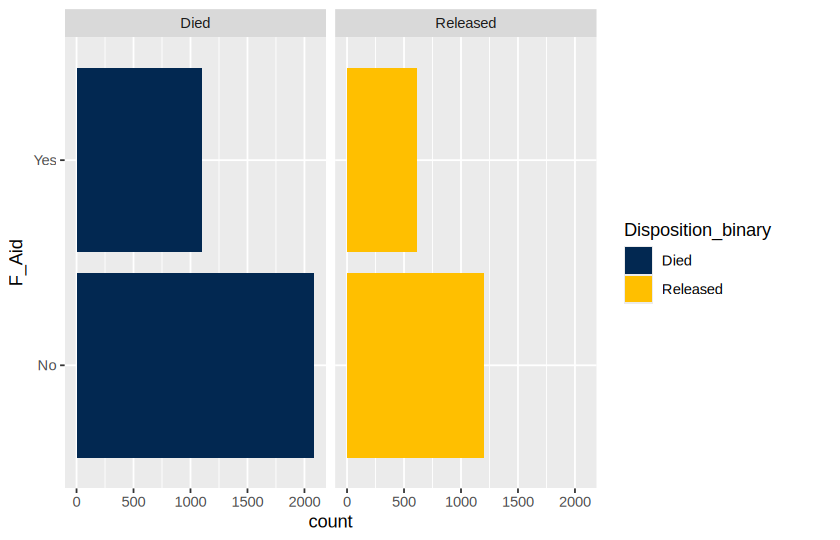

In [21]:
ggplot(df, aes(x = F_Aid, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [22]:
df <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,428
Nestling,Released,765
adult-like,Died,2762
adult-like,Released,1045


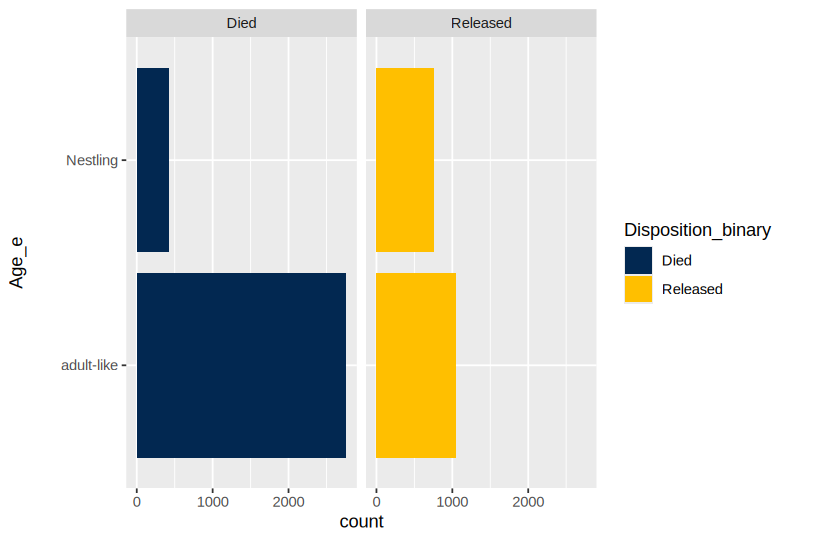

In [23]:
ggplot(df, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [24]:
df <- model_data %>%
  group_by(season, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

season,Disposition_binary,count
<chr>,<chr>,<int>
Fall,Died,376
Fall,Released,57
Spring,Died,1340
Spring,Released,956
Summer,Died,941
Summer,Released,600
Winter,Died,533
Winter,Released,197


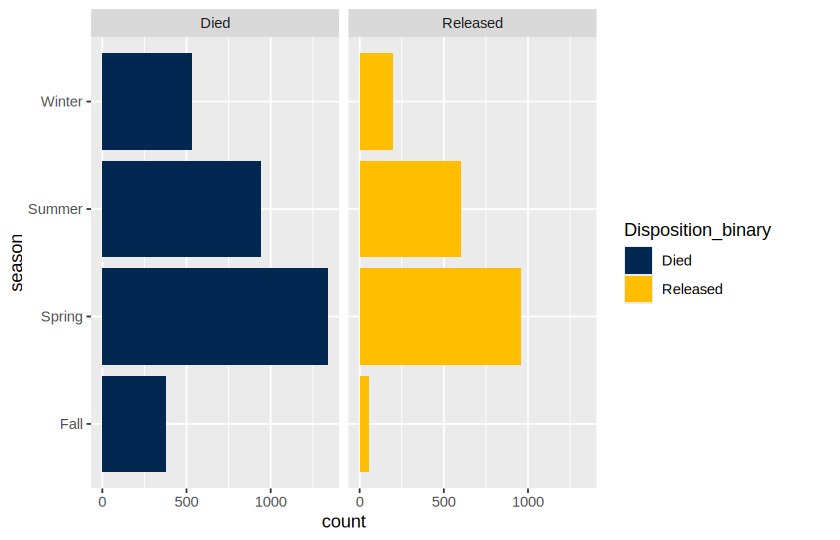

In [25]:
ggplot(df, aes(x = season, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:**
Age and season appear associated with the outcome survival but F_Aid does not really. nestling have much more realease rate than adult like bird. Survival was better in spring and summer. F_Aid shows similar death to release ratios.
A chi square test of indenpendence can check if these associations are statistically significant rather than due to chance

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2660,0.6420468
Lindsey,Released,1483,0.3579532
Santa Barbara,Died,38,0.5757576
Santa Barbara,Released,28,0.4242424
malibu,Died,492,0.6219975
malibu,Released,299,0.3780025


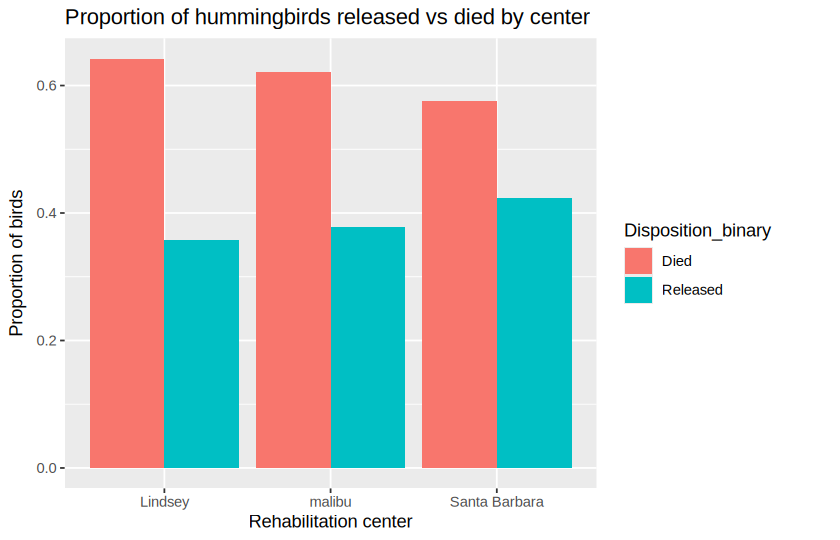

In [26]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation center") +
  ylab("Proportion of birds") +
  labs(title = "Proportion of hummingbirds released vs died by center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus                 4143                0
  Selasphorus                        0              857

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Species_group and Disposition_binary.
ℹ Output is grouped by Species_group.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Species_group, Disposition_binary))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


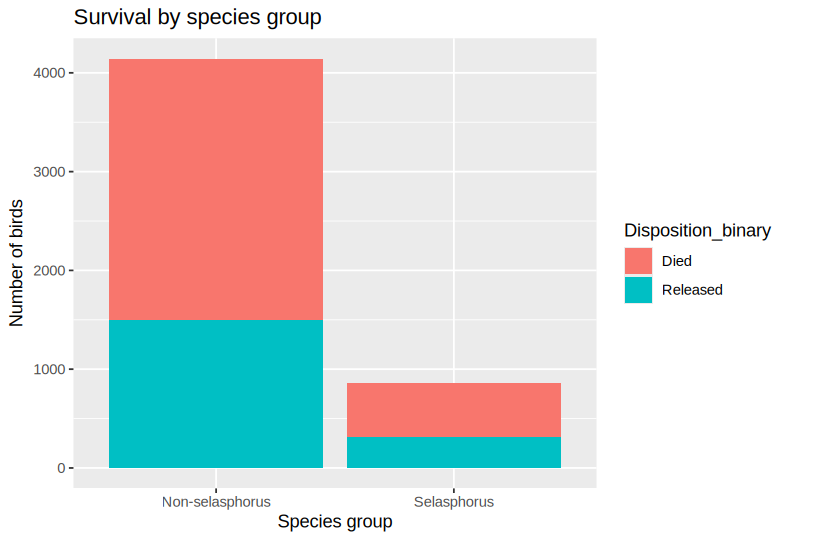

In [28]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID))

ggplot(species_distribution, aes(x = Species_group, y = count, fill = Disposition_binary)) +
  geom_col() +
  xlab("Species group") +
  ylab("Number of birds") +
  labs(title = "Survival by species group")

In [29]:
unique(model_data$Species_e)

[1] "ANHU"            "Non-selasphorus" "Selasphorus"     "BCHU"

✍️ **Your answer:**
The survival proportions do not differ between the 2 groups because if we are doing the porportion, in both gorups, about 36% were released and 63% died.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [30]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-28"

✍️ **Your answer:**
format argument tells that the raw text are written in the order month/day/year with 4 digit
If we used "%d/%m/%Y" instead, the order would have been day/month/year so days greater than 12 would be turned into NA


**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `Spring` Why?

because spring is the peak breeding and nesting season for hummingbirds,so many babie are found (fall from the nest) and brought into rehabilitation centers

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

Yes my prediction was right

In [31]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count = n_distinct(ID))

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count = n_distinct(ID))

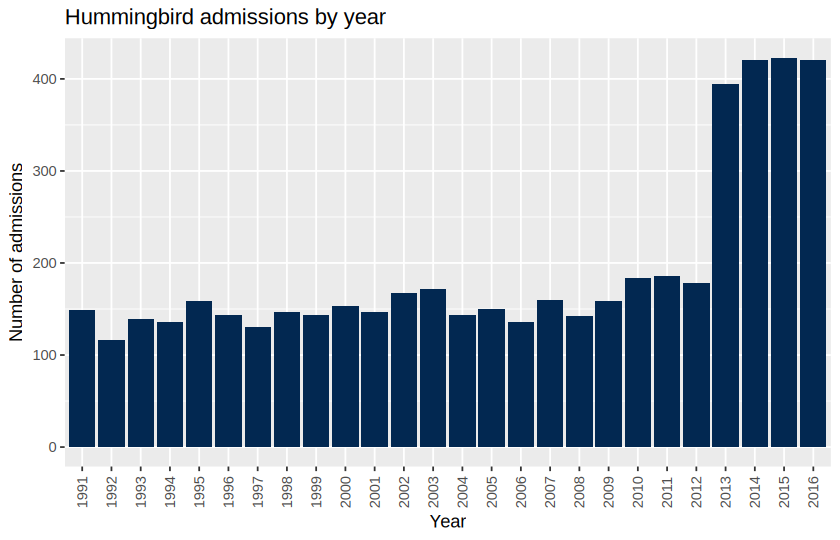


  Fall Spring Summer Winter 
   433   2296   1541    730 

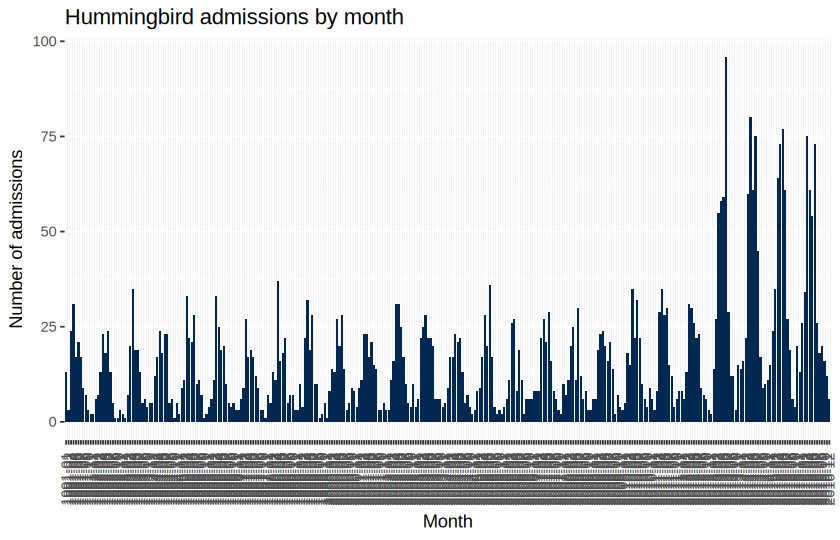

In [32]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Year") +
  ylab("Number of admissions") +
  labs(title ="Hummingbird admissions by year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way
ggplot(admissions_by_month, aes(x = Admitted_month, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Month") +
  ylab("Number of admissions") +
  labs(title = "Hummingbird admissions by month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
table(model_data$season)

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [33]:
# your investigation here

In [34]:
table(format(model_data$Admitted_date, "%Y"), model_data$Place)

      
       Lindsey malibu Santa Barbara
  1991     149      0             0
  1992     116      0             0
  1993     139      0             0
  1994     136      0             0
  1995     159      0             0
  1996     144      0             0
  1997     130      0             0
  1998     147      0             0
  1999     144      0             0
  2000     153      0             0
  2001     147      0             0
  2002     167      0             0
  2003     172      0             0
  2004     143      0             0
  2005     150      0             0
  2006     136      0             0
  2007     160      0             0
  2008     142      0             0
  2009     159      0             0
  2010     184      0             0
  2011     186      0             0
  2012     178      0             0
  2013     180    214             0
  2014     198    223             0
  2015     226    197             0
  2016     198    157            66

✍️ **Your answer:**
No the birds did not get into three times more trouble. They just strated to include more rehabilitation center (malibu and santa barbara)

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [35]:
class(data$Admitted)
table(data$Place, useNA = "ifany")
table(data$Disposition_binary, useNA = "ifany")

[1] "character"


      Lindsey        malibu Santa Barbara 
         5726          1088            94 


    Died Released 
    4423     2485 

✍️ **Your answer:**
The 3 problems in data are:
- dates stored as text
- capitalization no consistent for the malibu, and Lindsey
- missing labels in disposition_binary, replace blanks with NA

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:** what surprised me the most was the high mortality rate of adult-like hummingbirds compared to nestlings as I expected younger birds, more fragile, to have lower survival chances.
During the exercise I hit the error "object 'count' not found" because I passed the original model_data instead of the summurizerd admission_by_year so I fixed it by updating the first argument of ggplot() to use the summurized table so y = count

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [36]:
beep_colab("smb_stage_clear")   # mission complete 🍄

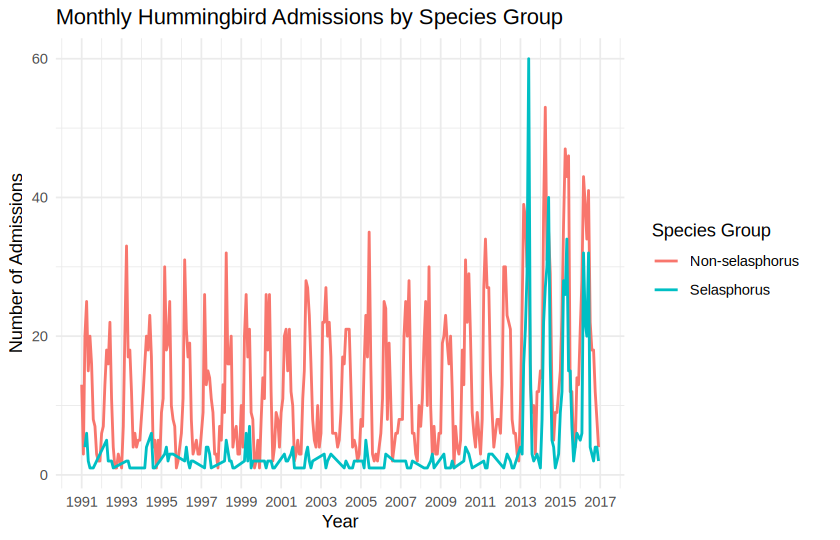

In [37]:
monthly_species <- model_data %>%
  mutate(
    Admitted_date = as.Date(Admitted, format = "%m/%d/%Y"),
    YearMonth = as.Date(format(Admitted_date, "%Y-%m-01"))
  ) %>%
  filter(!is.na(YearMonth), !is.na(Species_group)) %>%
  group_by(YearMonth, Species_group) %>%
  summarise(admissions = n(), .groups = "drop")


ggplot(monthly_species, aes(x = YearMonth, y = admissions, color = Species_group)) +
  geom_line(linewidth = 0.8) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  labs(
    title = "Monthly Hummingbird Admissions by Species Group",
    x = "Year",
    y = "Number of Admissions",
    color = "Species Group"
  ) +
  theme_minimal()

# Section 4: Running full model and model selection

1. Complete the code and fit a full model

In [40]:
fullmodel  = glm(as.factor(Disposition_binary)~ r + Green_Orange + season+F_Aid+Species_e, data = data, family= binomial(link = logit))
fullmodel


Call:  glm(formula = as.factor(Disposition_binary) ~ r + Green_Orange + 
    season + F_Aid + Species_e, family = binomial(link = logit), 
    data = data)

Coefficients:
                 (Intercept)                 rfound inside  
                    -1.96819                       0.20454  
        rfound on the ground                 rnest-related  
                     0.13826                       0.65101  
  rsuspect torpor-like state                      runknown  
                    -1.20462                       0.37968  
                 rwindow hit  Green_OrangeSelasphorus spp.  
                    -0.07535                       0.21180  
                seasonSpring                  seasonSummer  
                     1.10576                       1.01033  
                seasonWinter                      F_AidYes  
                     0.56752                      -0.09793  
               Species_eBCHU      Species_eNon-selasphorus  
                     0.43649       

2. use following command with full model to do stepwise model selection

In [41]:
backward_model = step(fullmodel,k=2,direction = "backward",test="Chisq")

Start:  AIC=8223.91
as.factor(Disposition_binary) ~ r + Green_Orange + season + F_Aid + 
    Species_e


Step:  AIC=8223.91
as.factor(Disposition_binary) ~ r + season + F_Aid + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
<none>           8195.9 8223.9                      
- F_Aid      1   8198.9 8224.9   2.965   0.08509 .  
- r          6   8280.3 8296.3  84.387 4.422e-16 ***
- season     3   8311.7 8333.7 115.826 < 2.2e-16 ***
- Species_e  3   8458.9 8480.9 262.941 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


In [42]:
forward_model = step(fullmodel,k=2,direction = ,test="Chisq")

Start:  AIC=8223.91
as.factor(Disposition_binary) ~ r + Green_Orange + season + F_Aid + 
    Species_e


Step:  AIC=8223.91
as.factor(Disposition_binary) ~ r + season + F_Aid + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
<none>           8195.9 8223.9                      
- F_Aid      1   8198.9 8224.9   2.965   0.08509 .  
- r          6   8280.3 8296.3  84.387 4.422e-16 ***
- season     3   8311.7 8333.7 115.826 < 2.2e-16 ***
- Species_e  3   8458.9 8480.9 262.941 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


### !!!Answer Questions in the Assignment

# Section 5: explore the glm object

In [ ]:
names(backward_model)

explore individual attributes of the fitted model and read about it in the R documentation

In [ ]:
library(sjPlot)

In [ ]:
tab_model(backward_model)